# Watching the bus drive in CARLA

Runs a full simulation on a CARLA town with the spectator camera locked to
the bus, so the CARLA window shows the bus being followed rather than a fixed
view of empty road.

Everything above the backend is the same code that runs on the synthetic map:
the same agent, policy, demand generator, metrics and abandonment. Only
`CarlaBackend` differs. That is what Phase 2's seam was for.

## Before you start

1. The CARLA server must be up — `docker compose up -d carla` from the
   project root.
2. **The server starts on Town10HD.** This notebook loads `TOWN` for you, but
   the first run after a server restart pays ten seconds or so for the load.
3. Watch the CARLA window, not this notebook. The run cell prints nothing
   until it finishes.

## How fast it goes

Rendering is what costs time, not the physics.

| | speed | a 10-request run |
|---|---|---|
| `SHOW_CAMERA = True` (rendering on) | ~4x real | ~9 minutes |
| `SHOW_CAMERA = False` (headless) | ~36x real | ~1 minute |

Measured on Town01. Note that running *slower* does not make the driving
better — that was tested directly, and wall-clock rate has no effect on the
simulation at all. See `roadmap.md`.

## Configuration

In [1]:
# =========================
# What to watch
# =========================
SHOW_CAMERA = True      # follow the bus; needs rendering, so ~9x slower
DRAW_STOPS = True       # mark the bus stops in the world

# =========================
# Where
# =========================
TOWN = "Town01"

# =========================
# The service
# =========================
MAX_REQUESTS = 10       # passengers over the whole run
DEMAND_INTERVAL_S = 90  # one new request every N simulated seconds
CAPACITY = 20
MAX_WAIT_S = 1800.0     # a passenger gives up after this
DWELL_S = 10.0          # how long the bus holds at each stop
SERVICE_WINDOW_S = 900.0  # the policy's own promise; see window_insertion

# =========================
# Traffic
# =========================
NPC_VEHICLES = 0        # each one costs throughput

# =========================
# Limits
# =========================
MAX_TIME_S = 3000.0     # safety ceiling in simulated seconds
FIXED_DELTA_S = 0.05    # physics step; never above 0.1
SEED = 0

# =========================
# Server
# =========================
CARLA_HOST = "localhost"
CARLA_PORT = 2000

## Preflight, and rescue

**Run this first.** As well as checking the server is reachable, it puts the
world back into asynchronous mode.

That matters: a run interrupted part-way — a kernel restart, an exception,
`Ctrl-C` — leaves CARLA in synchronous mode waiting for ticks that will never
come. The window then looks frozen and every other client hangs. This cell is
the fix, and it is safe to run at any time.

In [2]:
import time

import carla
import matplotlib.pyplot as plt

from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.experiment import run_trial
from src.map.CarlaMapProvider import CarlaMapProvider
from src.simulation.CarlaBackend import CarlaBackend, stop_positions_from


def revive(host=CARLA_HOST, port=CARLA_PORT):
    """
    Put the server back into asynchronous mode and clear stray actors.

    :param host: CARLA server host.
    :param port: CARLA server port.
    :return: The connected carla.World.
    """
    client = carla.Client(host, port)
    client.set_timeout(120.0)
    world = client.get_world()

    settings = world.get_settings()
    settings.synchronous_mode = False
    settings.no_rendering_mode = False
    settings.fixed_delta_seconds = None
    world.apply_settings(settings)
    client.get_trafficmanager().set_synchronous_mode(False)

    leftovers = [a for a in world.get_actors()
                 if a.type_id.startswith(("vehicle.", "walker."))]
    if leftovers:
        client.apply_batch_sync(
            [carla.command.DestroyActor(a) for a in leftovers], True)
    return world, client, len(leftovers)


world, client, cleared = revive()
print(f"server      {client.get_server_version()}")
print(f"map         {world.get_map().name}")
print(f"cleared     {cleared} leftover actors")
print(f"async mode  {not world.get_settings().synchronous_mode}")

server      0.9.16
map         Carla/Maps/Town01
cleared     1 leftover actors
async mode  True


## The map and its stops

Stops are hand-authored and version-controlled, one file per town, and are an
*input* to the map layer rather than something derived from it. See
`notebooks/carla-stop-authoring.ipynb` if you want to change them.

103 road nodes, 139 edges, 15 stops
map health: OK


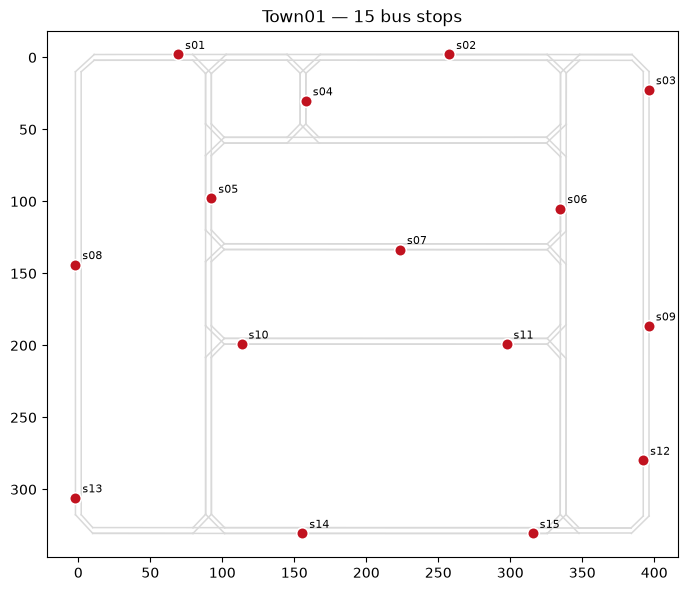

In [3]:
if TOWN not in world.get_map().name:
    print(f"loading {TOWN} ...")
    world = client.load_world(TOWN)

provider = CarlaMapProvider(TOWN)
positions = stop_positions_from(provider)
problems = provider.validate()

print(f"{len(provider.get_road_nodes())} road nodes, "
      f"{len(provider.get_road_edges())} edges, "
      f"{len(provider.get_stops())} stops")
print("map health:", "OK" if not problems else problems)

figure, axes = plt.subplots(figsize=(7, 7))
for entry, exit_wp in world.get_map().get_topology():
    a, b = entry.transform.location, exit_wp.transform.location
    axes.plot([a.x, b.x], [a.y, b.y], color="0.85", linewidth=1.1, zorder=1)
for stop in provider.get_stops():
    axes.scatter(stop.x, stop.y, s=70, color="#c1121f", zorder=3,
                 edgecolor="white", linewidth=1.2)
    axes.annotate(stop.name, (stop.x, stop.y), fontsize=8,
                  xytext=(5, 4), textcoords="offset points", zorder=4)
axes.set_aspect("equal")
axes.invert_yaxis()
axes.set_title(f"{TOWN} — {len(provider.get_stops())} bus stops")
plt.tight_layout()
plt.show()

## Mark the stops in the world

Draws a marker and label at each stop so you can see where the bus is heading
while you watch. Purely visual.

Markers are cleared whenever the map is reloaded, so re-run this if the world
is reloaded under you.

In [4]:
MARKER_MINUTES = 30

if DRAW_STOPS:
    for stop in provider.get_stops():
        world.debug.draw_point(
            carla.Location(x=stop.x, y=stop.y, z=stop.z + 0.5),
            size=0.3, color=carla.Color(255, 40, 40),
            life_time=MARKER_MINUTES * 60.0)
        world.debug.draw_string(
            carla.Location(x=stop.x, y=stop.y, z=stop.z + 3.0),
            stop.name, draw_shadow=True,
            color=carla.Color(255, 255, 0),
            life_time=MARKER_MINUTES * 60.0)
    print(f"drew {len(provider.get_stops())} markers "
          f"for {MARKER_MINUTES} minutes")
else:
    print("DRAW_STOPS is off")

drew 15 markers for 30 minutes


## Run it

**Watch the CARLA window now.** This cell prints nothing until the run
finishes.

What you should see: passengers appearing at stops as they request a ride,
the bus driving to collect them, holding for `DWELL_S` at each stop, and the
passengers vanishing as they board.

If the bus occasionally jumps a few metres, that is the stall recovery: a
vehicle that wedges against kerb geometry never frees itself, so it gets
lifted back onto the lane. Every one is counted below, because it is not
physics.

In [5]:
holder = {}


def build_backend(graph, start_stop_id):
    """
    Build the CARLA backend for this trial.

    :param graph: TransitGraph for the town, supplied by run_trial.
    :param start_stop_id: Node ID of the stop the bus starts at.
    :return: The backend.
    """
    backend = CarlaBackend(
        stop_positions=positions,
        position=start_stop_id,
        town=TOWN,
        host=CARLA_HOST,
        port=CARLA_PORT,
        fixed_delta_s=FIXED_DELTA_S,
        dwell_s=DWELL_S,
        npc_vehicles=NPC_VEHICLES,
        seed=SEED,
        no_rendering=not SHOW_CAMERA,
        follow_camera=SHOW_CAMERA,
    )
    holder["backend"] = backend
    return backend


started = time.perf_counter()
result = run_trial(
    policy_factory=lambda g: ReorderingInsertionPolicy(
        g, max_wait_s=SERVICE_WINDOW_S),
    provider=provider,
    backend_factory=build_backend,
    seed=SEED,
    max_requests=MAX_REQUESTS,
    demand_interval_s=DEMAND_INTERVAL_S,
    capacity=CAPACITY,
    max_wait_s=MAX_WAIT_S,
    dwell_s=DWELL_S,
    dt=1.0,
    max_time=MAX_TIME_S,
    silent=True,
)
wall = time.perf_counter() - started
print(f"done in {wall:.0f} s wall")

done in 645 s wall


## What happened

In [6]:
kpi = result.kpi
stats = holder["backend"].stats()


def seconds(value):
    """Format an optional number of seconds."""
    return "n/a" if value is None else f"{value:.0f} s"


print("service")
print(f"  requests            {MAX_REQUESTS}")
print(f"  fulfilled           {kpi.fulfilled_count}")
print(f"  abandoned           {kpi.cancelled_count}")
print(f"  served              {kpi.served_fraction:.0%}")
print(f"  mean wait           {seconds(kpi.mean_wait_time)}")
print(f"  mean ride           {seconds(kpi.mean_ride_time)}")
print()
print("driving")
print(f"  stops reached       {stats['arrivals']:.0f}")
print(f"  distance            {stats['distance_m'] / 1000:.2f} km")
print(f"  simulated           {result.tick_count} s")
print(f"  real time factor    {result.tick_count / wall:.1f}x")
print()
print("passengers rendered")
print(f"  walkers spawned     {stats['walkers_spawned']:.0f}")
print(f"  walkers removed     {stats['walkers_removed']:.0f}")
print(f"  spawn failures      {stats['walker_spawn_failures']:.0f}")
print()
print("recovery (not physics — lower is better)")
print(f"  re-routed           {stats['repaths']:.0f}")
print(f"  lifted back on lane {stats['unwedges']:.0f}")

service
  requests            10
  fulfilled           10
  abandoned           0
  served              100%
  mean wait           573 s
  mean ride           244 s

driving
  stops reached       16
  distance            8.25 km
  simulated           2147 s
  real time factor    3.3x

passengers rendered
  walkers spawned     10
  walkers removed     10
  spawn failures      0

recovery (not physics — lower is better)
  re-routed           78
  lifted back on lane 12


## Afterwards

`run_trial` closes the backend for you, which destroys every actor and
restores the world's settings. Run the cell below anyway if something looked
wrong — it is the same rescue as the preflight cell.

### If it looks frozen

The world is in synchronous mode with nobody ticking it. Run the cell below.

### If the bus barely moves

Check the vehicle. The only blueprint CARLA tags as a bus is wider than
Town01's lanes and cannot get round the town at all — `CarlaBackend` defaults
to a minibus for that reason. See `roadmap.md`.

In [7]:
world, client, cleared = revive()
print(f"cleared {cleared} actors; async mode "
      f"{not world.get_settings().synchronous_mode}")

cleared 0 actors; async mode True
